In [2]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets, get_max_coords
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.stats import lognorm_mode, lognorm_mode_with_error
from shared.thickness import gaussian
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [3]:
#Defining all the required functions



#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625






--- beta = 0.0625, t = 40 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 45 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 50 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 55 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 60 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 65 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 70 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 75 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 80 ---
  loading cached filtered fields...

--- beta = 0.0625, t = 85 ---
  loading cached filtered fields...

--- beta = 1, t = 40 ---
  loading cached filtered fields...

--- beta = 1, t = 45 ---
  loading cached filtered fields...

--- beta = 1, t = 50 ---
  loading cached filtered fields...

--- beta = 1, t = 55 ---
  loading cached filtered fields...

--- beta = 1, t = 60 ---
  loading cached filtered fields...

--- beta = 1, t = 6

KeyboardInterrupt: 

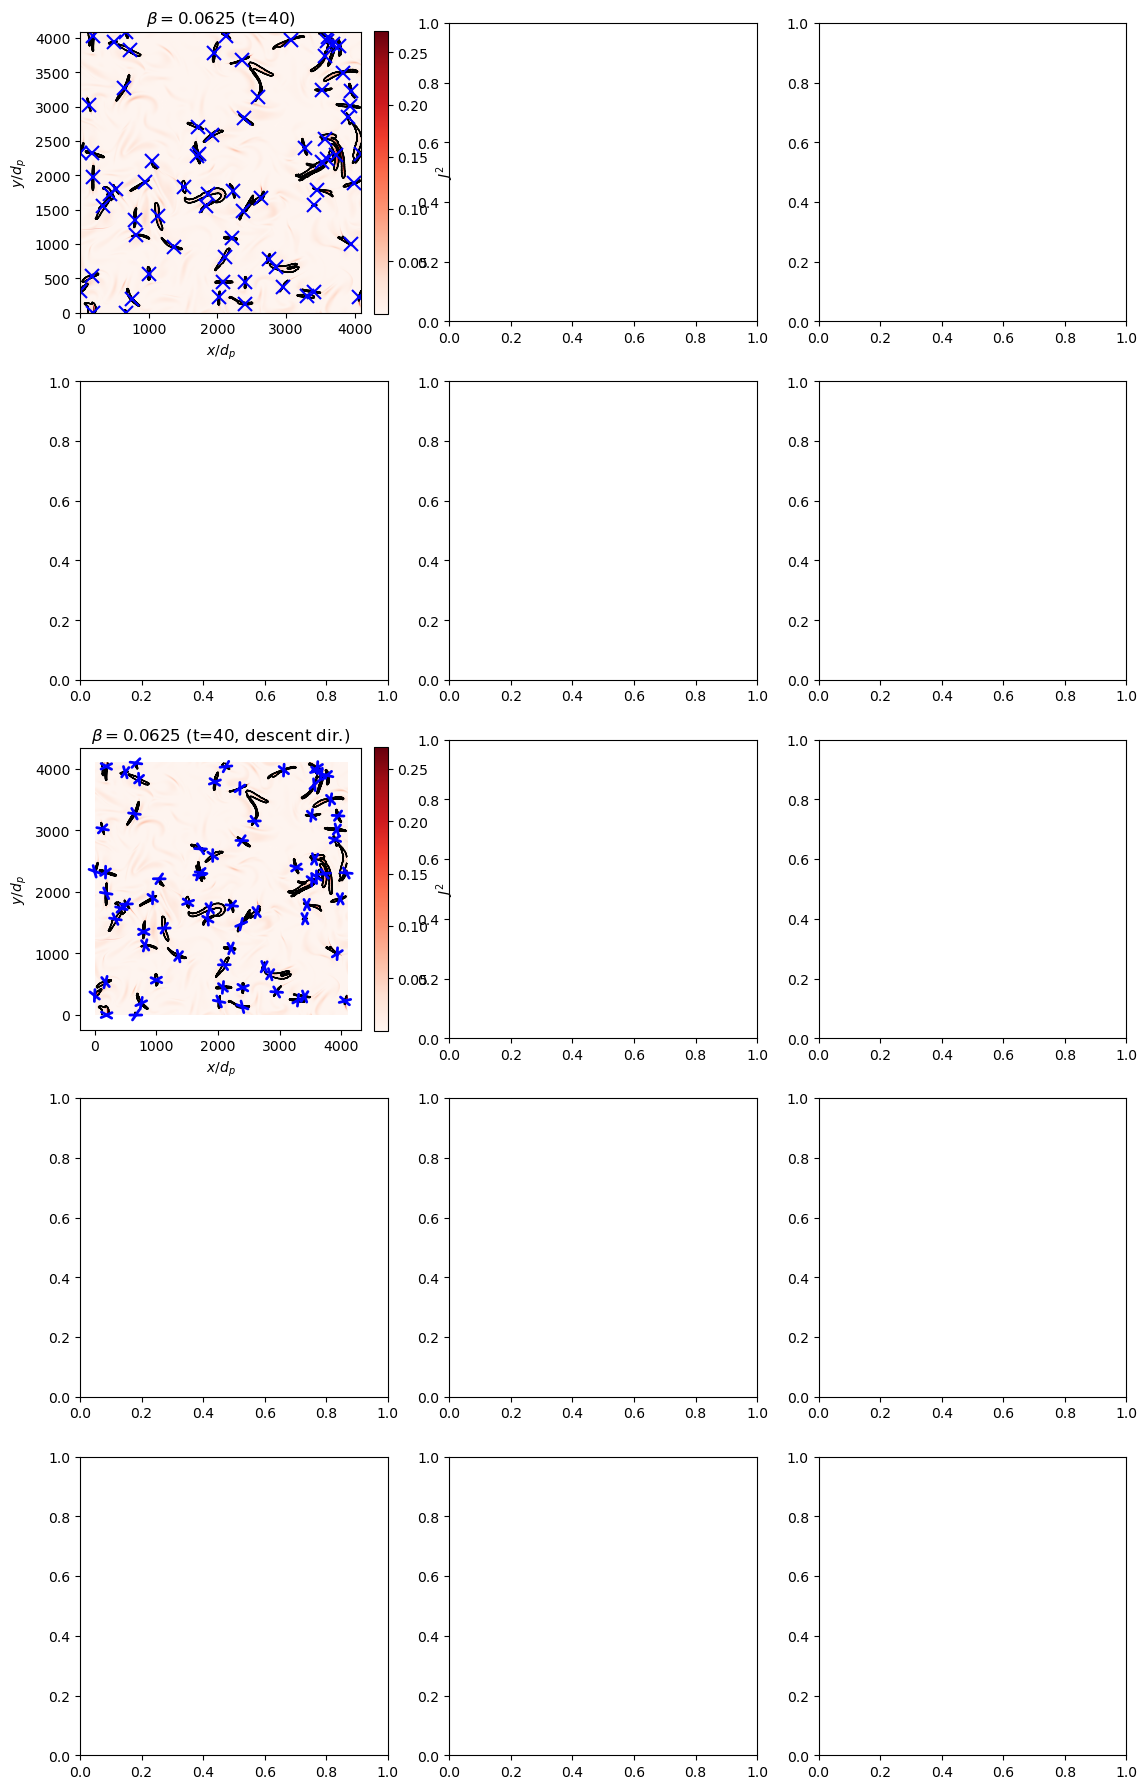

In [4]:
# =====================================================
# STAGE 1: load fields + detect sheets for all (beta, t)
# =====================================================
betas     = [0.0625, 1, 16]
snapshots = [40, 45, 50, 55, 60, 65, 70, 75, 80, 85]
t_ref     = 40   # reference snapshot for the image rows

cache_dir = str(CACHE / "filtered_cache")
os.makedirs(cache_dir, exist_ok=True)

J2_all   = {}    # keyed by (beta, t)
mask_all = {}    # keyed by (beta, t)

for beta in betas:
    if beta == 0.0625:
        n_iter, Xi = 1, 1.6
    elif beta == 1:
        n_iter, Xi = 2, 2.0
    else:
        n_iter, Xi = 3, 2.0

    for t in snapshots:
        print(f"\n--- beta = {beta}, t = {t} ---")
        base_path = f'{DATA_ROOT}/beta_p_{beta}/beta_e_1/'
        File_Bx = base_path + f'Bx_ApJ_t{t}.h5'
        File_By = base_path + f'By_ApJ_t{t}.h5'
        File_Bz = base_path + f'Bz_ApJ_t{t}.h5'

        cache_file = f"{cache_dir}/filtered_beta_{beta}_t{t}_iter{n_iter}_Xi{Xi}.npz"

        if os.path.exists(cache_file):
            print("  loading cached filtered fields...")
            data = np.load(cache_file)
            data_Bx_f = data['Bx']
            data_By_f = data['By']
            data_Bz_f = data['Bz']
        else:
            print("  computing filtering (slow)...")
            with h5py.File(File_Bx, 'r') as fBx, \
                 h5py.File(File_By, 'r') as fBy, \
                 h5py.File(File_Bz, 'r') as fBz:
                data_Bx = fBx['DS1'][:].T
                data_By = fBy['DS1'][:].T
                data_Bz = fBz['DS1'][:].T
            data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
                data_Bx, data_By, data_Bz, n_iter, Xi=Xi
            )
            np.savez_compressed(cache_file,
                                Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f)

        # current density
        Jx = partial_y_fft(data_Bz_f, dx)
        Jy = -partial_x_fft(data_Bz_f, dy)
        Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
        J2 = Jx**2 + Jy**2 + Jz**2

        # detection + cleanup
        sheets = detect_current_sheets(J2)
        mask = np.zeros_like(J2)
        for sheet in sheets:
            for (i, j) in sheet:
                mask[i, j] = 1
        struct = morphology.disk(5)
        mask = morphology.binary_opening(mask, struct)
        mask = morphology.binary_closing(mask, struct)
        mask = morphology.remove_small_objects(
            mask.astype(bool), min_size=500
        ).astype(int)

        J2_all[(beta, t)]   = J2
        mask_all[(beta, t)] = mask

# global colour scale across ALL snapshots and betas
all_values = np.concatenate([J2_all[k].ravel() for k in J2_all])
vmax_global = np.percentile(all_values, 99)


# =====================================================
# STAGE 2: pooled M1 / M2 / M3 analysis
# =====================================================

# ---- params ----
max_len      = 60
sigma_smooth = 3
step_size    = 1
max_steps    = 1000
factor       = 200.0   # arrow length in image rows

parent_save_folder = str(RESULTS / "gaussian_fits_J2_NR")
os.makedirs(parent_save_folder, exist_ok=True)

# ---- main figure ----
fig, axes = plt.subplots(5, len(betas), figsize=(4.5*len(betas), 22.5))
if len(betas) == 1:
    axes = axes.reshape(5, 1)


for idx, beta in enumerate(betas):
    ax_img_m1  = axes[0, idx]
    ax_hist_m1 = axes[1, idx]
    ax_img_m2  = axes[2, idx]
    ax_hist_m2 = axes[3, idx]
    ax_hist_m3 = axes[4, idx]

    # ----------------------------------------
    # IMAGE ROWS — drawn from the reference snapshot only
    # ----------------------------------------
    cleaned_mask_ref = mask_all[(beta, t_ref)]
    J2_ref           = J2_all[(beta, t_ref)]
    max_coords_ref, labeled_mask_ref = get_max_coords(cleaned_mask_ref, J2_ref)
    boundaries_ref = find_boundaries(labeled_mask_ref)

    # Row 0 — field + maxima
    # ax_img_m1.imshow(J2_ref.T, cmap='seismic', origin='lower', vmax=vmax_global)
    # ax_img_m1.contour(boundaries_ref.T, levels=[0.5], colors='white', linewidths=1)
    # for x, y in max_coords_ref:
    #     ax_img_m1.plot(x, y, marker='x', markersize=10,
    #                    markeredgewidth=1.5, color='yellow')
    # ax_img_m1.set_title(rf'$\beta = {beta}$ (t={t_ref})')
    # ax_img_m1.set_xlabel(r'$x/d_p$')
    # ax_img_m1.set_ylabel(r'$y/d_p$')

    # Row 0 — field + maxima
    im_m1 = ax_img_m1.imshow(J2_ref.T, cmap='Reds', origin='lower', vmax=vmax_global)
    ax_img_m1.contour(boundaries_ref.T, levels=[0.5], colors='black', linewidths=1)
    for x, y in max_coords_ref:
        ax_img_m1.plot(x, y, marker='x', markersize=10,
                       markeredgewidth=1.5, color='blue')
    ax_img_m1.set_title(rf'$\beta = {beta}$ (t={t_ref})')
    ax_img_m1.set_xlabel(r'$x/d_p$')
    ax_img_m1.set_ylabel(r'$y/d_p$')
    cbar_m1 = fig.colorbar(im_m1, ax=ax_img_m1, fraction=0.046, pad=0.04)
    cbar_m1.set_label(r'$J^2$')

    # Descent directions for the reference frame (used only for arrows)
    J2_smooth_ref   = gaussian_filter(J2_ref, sigma=sigma_smooth)
    dJdx_ref, dJdy_ref = np.gradient(J2_smooth_ref)
    descent_dirs_ref = []
    for (x, y) in max_coords_ref:
        grad = np.array([dJdx_ref[x, y], dJdy_ref[x, y]])
        if np.allclose(grad, 0):
            descent_dirs_ref.append(np.array([0.0, 0.0]))
        else:
            descent_dirs_ref.append(-grad / np.linalg.norm(grad))

    # Row 2 — field + descent arrows
    # ax_img_m2.imshow(J2_ref.T, cmap='seismic', origin='lower',
    #                  vmax=vmax_global, aspect='equal', zorder=0)
    # ax_img_m2.contour(boundaries_ref.T, levels=[0.5], colors='white',
    #                   linewidths=1, zorder=2)
    # for (x, y), (dx, dy) in zip(max_coords_ref, descent_dirs_ref):
    #     start = (x - 0.5*factor*dx, y - 0.5*factor*dy)
    #     end   = (x + 0.5*factor*dx, y + 0.5*factor*dy)
    #     arrow = FancyArrowPatch(start, end, arrowstyle="<->",
    #                             color="red", mutation_scale=10,
    #                             linewidth=2, zorder=10)
    #     ax_img_m2.add_patch(arrow)
    # ax_img_m2.set_title(rf'$\beta = {beta}$ (t={t_ref}, descent dir.)')
    # ax_img_m2.set_xlabel(r'$x/d_p$')
    # ax_img_m2.set_ylabel(r'$y/d_p$')

    # Row 2 — field + descent arrows
    im_m2 = ax_img_m2.imshow(J2_ref.T, cmap='Reds', origin='lower',
                             vmax=vmax_global, aspect='equal', zorder=0)
    ax_img_m2.contour(boundaries_ref.T, levels=[0.5], colors='black',
                      linewidths=1, zorder=2)
    for (x, y), (dx, dy) in zip(max_coords_ref, descent_dirs_ref):
        start = (x - 0.5*factor*dx, y - 0.5*factor*dy)
        end   = (x + 0.5*factor*dx, y + 0.5*factor*dy)
        arrow = FancyArrowPatch(start, end, arrowstyle="<->",
                                color="blue", mutation_scale=10,
                                linewidth=2, zorder=10)
        ax_img_m2.add_patch(arrow)
    ax_img_m2.set_title(rf'$\beta = {beta}$ (t={t_ref}, descent dir.)')
    ax_img_m2.set_xlabel(r'$x/d_p$')
    ax_img_m2.set_ylabel(r'$y/d_p$')
    cbar_m2 = fig.colorbar(im_m2, ax=ax_img_m2, fraction=0.046, pad=0.04)
    cbar_m2.set_label(r'$J^2$')

    # ----------------------------------------
    # POOLED THICKNESSES across all snapshots
    # ----------------------------------------
    thicknesses_m1_pooled = []
    thicknesses_m2_pooled = []
    thicknesses_m3_pooled = []

    for t in snapshots:
        cleaned_mask = mask_all[(beta, t)]
        J2           = J2_all[(beta, t)]
        max_coords, _ = get_max_coords(cleaned_mask, J2)

        # ---- M1: distance transform per region ----
        labeled_mask_m1 = measure.label(cleaned_mask, connectivity=2)
        for label_id in range(1, labeled_mask_m1.max() + 1):
            region = (labeled_mask_m1 == label_id)
            dist = ndi.distance_transform_edt(region)
            thicknesses_m1_pooled.append(2 * dist.max())

        # ---- descent directions for this (beta, t) ----
        J2_smooth = gaussian_filter(J2, sigma=sigma_smooth)
        dJdx, dJdy = np.gradient(J2_smooth)
        descent_dirs = []
        for (x, y) in max_coords:
            grad = np.array([dJdx[x, y], dJdy[x, y]])
            if np.allclose(grad, 0):
                descent_dirs.append(np.array([0.0, 0.0]))
            else:
                descent_dirs.append(-grad / np.linalg.norm(grad))

        # ---- M2: walk along descent direction ----
        for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
            x0f, y0f = float(x0), float(y0)

            # forward
            xf, yf, steps = x0f, y0f, 0
            while steps < max_steps:
                xf_new = xf + dx*step_size
                yf_new = yf + dy*step_size
                xi, yi = int(round(xf_new)), int(round(yf_new))
                if (xi < 0 or yi < 0 or
                    xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                    break
                if not cleaned_mask[xi, yi]:
                    break
                xf, yf = xf_new, yf_new
                steps += 1
            dist_forward = np.hypot(xf - x0f, yf - y0f)

            # backward
            xb, yb, steps = x0f, y0f, 0
            while steps < max_steps:
                xb_new = xb - dx*step_size
                yb_new = yb - dy*step_size
                xi, yi = int(round(xb_new)), int(round(yb_new))
                if (xi < 0 or yi < 0 or
                    xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
                    break
                if not cleaned_mask[xi, yi]:
                    break
                xb, yb = xb_new, yb_new
                steps += 1
            dist_backward = np.hypot(xb - x0f, yb - y0f)

            total = dist_forward + dist_backward
            if total > 0:
                thicknesses_m2_pooled.append(total)

        # ---- M3: Gaussian-fit profile + save every fit ----
        beta_t_save_folder = os.path.join(
            parent_save_folder, f"beta_{beta}", f"t{t}"
        )
        os.makedirs(beta_t_save_folder, exist_ok=True)
        for i, ((x, y), (dx, dy)) in enumerate(zip(max_coords, descent_dirs)):
            if dx == 0 and dy == 0:
                continue
            xs, vals = [], []
            for k in range(-max_len, max_len + 1):
                xc = x + k*dx
                yc = y + k*dy
                xi, yi = int(round(xc)), int(round(yc))
                if 0 <= xi < J2.shape[0] and 0 <= yi < J2.shape[1]:
                    xs.append(k)
                    vals.append(J2[xi, yi])
            xs = np.array(xs); vals = np.array(vals)
            if len(vals) < 3:
                continue
            A0 = vals.max() - vals.min()
            mu0 = xs[np.argmax(vals)]
            sigma0 = max_len / 4
            B0 = vals.min()
            try:
                popt, pcov = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
            except RuntimeError:
                continue

            A, mu, sigma_fit, B = popt
            perr = np.sqrt(np.diag(pcov))
            A_err, mu_err, sigma_err, B_err = perr

            # reduced chi-square as a fit-quality number
            residuals = vals - gaussian(xs, *popt)
            dof = len(vals) - 4
            chi2_red = np.sum(residuals**2) / dof if dof > 0 else np.nan

            k_fwhm   = 2*np.sqrt(2*np.log(2))
            fwhm     = k_fwhm * np.abs(sigma_fit)
            fwhm_err = k_fwhm * sigma_err

            if 0 < fwhm <= 100:
                thicknesses_m3_pooled.append(fwhm)

            # save the fit plot with the uncertainty annotated
            x_dense = np.linspace(xs.min(), xs.max(), 500)
            fit_curve = A*np.exp(-(x_dense - mu)**2 / (2*sigma_fit**2)) + B

            # 1-sigma band on the fitted curve from the sigma uncertainty
            upper = A*np.exp(-(x_dense - mu)**2 / (2*(sigma_fit+sigma_err)**2)) + B
            lower = A*np.exp(-(x_dense - mu)**2 / (2*max(sigma_fit-sigma_err, 1e-9)**2)) + B

            fig_fit, ax_fit = plt.subplots()
            ax_fit.plot(xs, vals, 'o', label="sampled profile")
            ax_fit.plot(x_dense, fit_curve, label="Gaussian fit")
            ax_fit.fill_between(x_dense, lower, upper, alpha=0.2,
                                color='tab:orange', label=r"$\pm 1\sigma$ on width")

            # vertical markers showing the FWHM span and its uncertainty
            half_max = B + A/2
            ax_fit.axhline(half_max, color='grey', linestyle=':', linewidth=1)
            ax_fit.axvspan(mu - fwhm/2, mu + fwhm/2, alpha=0.08, color='tab:green')

            ax_fit.set_title(
                f"beta={beta}, t={t}, sample {i}\n"
                f"FWHM = {fwhm:.2f} ± {fwhm_err:.2f} px"
                f"   |   $\\sigma$ = {sigma_fit:.2f} ± {sigma_err:.2f}"
                f"   |   $\\chi^2_\\nu$ = {chi2_red:.2f}"
            )
            ax_fit.set_xlabel("t (pixels)")
            ax_fit.set_ylabel("Intensity")
            ax_fit.legend(fontsize=8)
            fig_fit.tight_layout()
            fig_fit.savefig(os.path.join(beta_t_save_folder, f"fit_{i:03d}.png"))
            plt.close(fig_fit)

    # ---- pooled stats ----
    if thicknesses_m1_pooled:
        a = np.array(thicknesses_m1_pooled)
        print(f"[beta={beta}] M1 pooled (N={len(a)}) "
              f"mean={a.mean():.3f}, median={np.median(a):.3f}, "
              f"min={a.min():.3f}, max={a.max():.3f}")
    if thicknesses_m2_pooled:
        a = np.array(thicknesses_m2_pooled)
        print(f"[beta={beta}] M2 pooled (N={len(a)}) "
              f"mean={a.mean():.3f}, median={np.median(a):.3f}, "
              f"min={a.min():.3f}, max={a.max():.3f}")
    if thicknesses_m3_pooled:
        a = np.array(thicknesses_m3_pooled)
        print(f"[beta={beta}] M3 pooled (N={len(a)}) "
              f"mean={a.mean():.3f}, median={np.median(a):.3f}, "
              f"min={a.min():.3f}, max={a.max():.3f}")

    # ---- ROW 1: M1 PDF ----
    # x_m1_di = np.array(thicknesses_m1_pooled)
    # x_m1_di = x_m1_di[x_m1_di > 0] / 16.0
    # if x_m1_di.size > 0:
    #     shape_m1, loc_m1, scale_m1 = lognorm.fit(x_m1_di, floc=0)
    #     xs_fit = np.linspace(0, x_m1_di.max(), 300)
    #     ax_hist_m1.hist(x_m1_di, bins=20, density=True, alpha=0.4, label="Histogram")
    #     ax_hist_m1.plot(xs_fit, lognorm.pdf(xs_fit, shape_m1, loc_m1, scale_m1),
    #                     label="Log-normal fit")
    #     ax_hist_m1.legend()
    # ax_hist_m1.set_xlabel(r"$d_i$")
    # ax_hist_m1.set_ylabel("Probability density")
    # ax_hist_m1.set_title(rf'M1 PDF ($\beta = {beta}$, pooled)')

    # ---- ROW 1: M1 PDF ----
    x_m1_di = np.array(thicknesses_m1_pooled)
    x_m1_di = x_m1_di[x_m1_di > 0] / 16.0
    if x_m1_di.size > 0:
        shape_m1, loc_m1, scale_m1 = lognorm.fit(x_m1_di, floc=0)
        xs_fit = np.linspace(0, x_m1_di.max(), 300)
        ax_hist_m1.hist(x_m1_di, bins=20, density=True, alpha=0.4, label="Histogram")
        ax_hist_m1.plot(xs_fit, lognorm.pdf(xs_fit, shape_m1, loc_m1, scale_m1),
                        label="Log-normal fit")
        # mode_m1 = lognorm_mode(shape_m1, scale_m1)
        mode_m1, mode_err_m1 = lognorm_mode_with_error(x_m1_di)
        ax_hist_m1.axvline(mode_m1, color='k', linestyle='--', linewidth=1,
                           label=f"Mode = {mode_m1:.3f} ± {mode_err_m1:.3f}")
        # shaded band showing the 1-sigma uncertainty on the mode
        ax_hist_m1.axvspan(mode_m1 - mode_err_m1, mode_m1 + mode_err_m1,
                           color='k', alpha=0.12)
        ax_hist_m1.legend()
    ax_hist_m1.set_xlabel(r"$d_i$")
    ax_hist_m1.set_ylabel("Probability density")
    ax_hist_m1.set_title(rf'M1 PDF ($\beta = {beta}$, pooled)')

    # ---- ROW 3: M2 PDF ----
    # x_m2_di = np.array(thicknesses_m2_pooled)
    # x_m2_di = x_m2_di[x_m2_di > 0] / 16.0
    # if x_m2_di.size > 0:
    #     shape_m2, loc_m2, scale_m2 = lognorm.fit(x_m2_di, floc=0)
    #     xs_fit = np.linspace(0, x_m2_di.max(), 300)
    #     ax_hist_m2.hist(x_m2_di, bins=20, density=True, alpha=0.4, label="Histogram")
    #     ax_hist_m2.plot(xs_fit, lognorm.pdf(xs_fit, shape_m2, loc_m2, scale_m2),
    #                     label="Log-normal fit")
    #     ax_hist_m2.legend()
    # ax_hist_m2.set_xlabel(r"$d_i$")
    # ax_hist_m2.set_ylabel("Probability density")
    # ax_hist_m2.set_title(rf'M2 PDF ($\beta = {beta}$, pooled)')

    # ---- ROW 3: M2 PDF ----
    x_m2_di = np.array(thicknesses_m2_pooled)
    x_m2_di = x_m2_di[x_m2_di > 0] / 16.0
    if x_m2_di.size > 0:
        shape_m2, loc_m2, scale_m2 = lognorm.fit(x_m2_di, floc=0)
        xs_fit = np.linspace(0, x_m2_di.max(), 300)
        ax_hist_m2.hist(x_m2_di, bins=20, density=True, alpha=0.4, label="Histogram")
        ax_hist_m2.plot(xs_fit, lognorm.pdf(xs_fit, shape_m2, loc_m2, scale_m2),
                        label="Log-normal fit")
        mode_m2, mode_err_m2 = lognorm_mode_with_error(x_m2_di)
        ax_hist_m2.axvline(mode_m2, color='k', linestyle='--', linewidth=1,
                           label=f"Mode = {mode_m2:.3f} ± {mode_err_m2:.3f}")
        ax_hist_m2.axvspan(mode_m2 - mode_err_m2, mode_m2 + mode_err_m2,
                           color='k', alpha=0.12)
        ax_hist_m2.legend()
    ax_hist_m2.set_xlabel(r"$d_i$")
    ax_hist_m2.set_ylabel("Probability density")
    ax_hist_m2.set_title(rf'M2 PDF ($\beta = {beta}$, pooled)')

    # ---- ROW 4: M3 PDF ----
    # x_m3_di = np.array(thicknesses_m3_pooled) / 16.0
    # if x_m3_di.size > 0:
    #     shape_m3, loc_m3, scale_m3 = lognorm.fit(x_m3_di, floc=0)
    #     xs_fit = np.linspace(0, x_m3_di.max(), 300)
    #     ax_hist_m3.hist(x_m3_di, bins=20, density=True, alpha=0.4, label="Histogram")
    #     ax_hist_m3.plot(xs_fit, lognorm.pdf(xs_fit, shape_m3, loc_m3, scale_m3),
    #                     label="Log-normal fit")
    #     ax_hist_m3.legend()
    # ax_hist_m3.set_xlabel(r"$d_i$")
    # ax_hist_m3.set_ylabel("Probability density")
    # ax_hist_m3.set_title(rf'M3 PDF ($\beta = {beta}$, pooled)')

    # ---- ROW 4: M3 PDF ----
    x_m3_di = np.array(thicknesses_m3_pooled) / 16.0
    if x_m3_di.size > 0:
        shape_m3, loc_m3, scale_m3 = lognorm.fit(x_m3_di, floc=0)
        xs_fit = np.linspace(0, x_m3_di.max(), 300)
        ax_hist_m3.hist(x_m3_di, bins=20, density=True, alpha=0.4, label="Histogram")
        ax_hist_m3.plot(xs_fit, lognorm.pdf(xs_fit, shape_m3, loc_m3, scale_m3),
                        label="Log-normal fit")
        mode_m3, mode_err_m3 = lognorm_mode_with_error(x_m3_di)
        ax_hist_m3.axvline(mode_m3, color='k', linestyle='--', linewidth=1,
                           label=f"Mode = {mode_m3:.3f} ± {mode_err_m3:.3f}")
        ax_hist_m3.axvspan(mode_m3 - mode_err_m3, mode_m3 + mode_err_m3,
                           color='k', alpha=0.12)
        ax_hist_m3.legend()
    ax_hist_m3.set_xlabel(r"$d_i$")
    ax_hist_m3.set_ylabel("Probability density")
    ax_hist_m3.set_title(rf'M3 PDF ($\beta = {beta}$, pooled)')


plt.tight_layout()
plt.savefig(RESULTS / "J2_NR_M1_M2_M3_pooled.png", dpi=300)
plt.show()